# Gradient Descent from Scratch

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nathanmaulding/tutorial-projects/blob/main/gradient-descent/gradient_descent_from_scratch.ipynb)

Almost every modern machine-learning model, from a straight line up to a large language model, is trained with some form of **gradient descent**. In this notebook we build it by hand, with nothing but `numpy`, on the simplest problem possible: fitting a line to noisy points.

**What you'll learn**

1. What a *model*, *parameters* and a *loss function* are
2. What a *gradient* is, and how to check one numerically
3. The gradient descent update rule, and watching it walk downhill
4. Why the *learning rate* matters (too small, just right, too big)
5. How the answer compares with the exact closed-form solution
6. Stochastic (mini-batch) gradient descent, the version used in practice

**Runtime:** under a minute on any laptop or free Colab. No GPU, no API keys.

> 🎬 *Video walkthrough: coming soon.*

## 0. Setup

We fix the random seed so your numbers match the video exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)
plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. The problem: fit a line

We make up data from a line we know, $y = 3x + 2$, plus some noise. Then we pretend we *don't* know the 3 and the 2, and try to recover them from the data alone.

Our **model** is a line with two **parameters**: a slope $w$ and an intercept $b$:

$$\hat{y} = w\,x + b$$

Learning means finding the values of $w$ and $b$ that make $\hat{y}$ close to the real $y$.

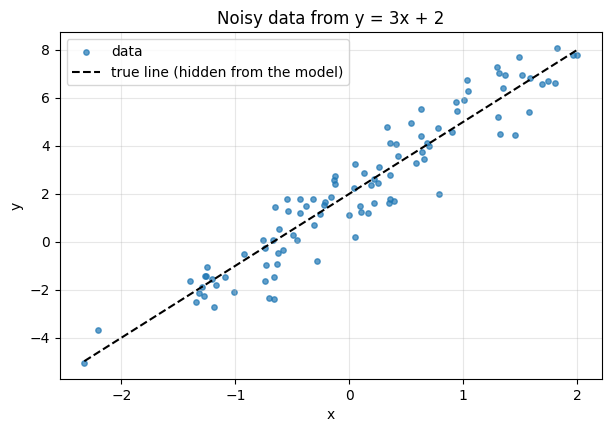

In [2]:
TRUE_W, TRUE_B = 3.0, 2.0
n = 100

x = rng.normal(0, 1, size=n)                        # inputs
y = TRUE_W * x + TRUE_B + rng.normal(0, 1, size=n)  # outputs = line + noise

plt.scatter(x, y, s=15, alpha=0.7, label="data")
xs = np.linspace(x.min(), x.max(), 2)
plt.plot(xs, TRUE_W * xs + TRUE_B, "k--", label="true line (hidden from the model)")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.title("Noisy data from y = 3x + 2")
plt.show()

## 2. The loss function: one number for "how wrong"

To improve, we need a single number that says how bad a guess $(w, b)$ is. The standard choice for regression is the **mean squared error (MSE)**:

$$L(w, b) = \frac{1}{n}\sum_{i=1}^{n} \big(w\,x_i + b - y_i\big)^2$$

Squaring makes every error positive and punishes big misses more than small ones. Lower is better, and the best line sits at the **bottom** of this function.

In [3]:
def predict(w, b, x):
    return w * x + b

def mse_loss(w, b, x, y):
    return np.mean((predict(w, b, x) - y) ** 2)

print(f"Loss of a bad guess   (w=0, b=0): {mse_loss(0, 0, x, y):.3f}")
print(f"Loss of the true line (w=3, b=2): {mse_loss(TRUE_W, TRUE_B, x, y):.3f}")

Loss of a bad guess   (w=0, b=0): 14.359
Loss of the true line (w=3, b=2): 0.916


Because there are only two parameters, we can actually **draw** the loss for every $(w, b)$ as a landscape. Each contour line joins points with equal loss. Training is a walk to the bottom of this bowl.

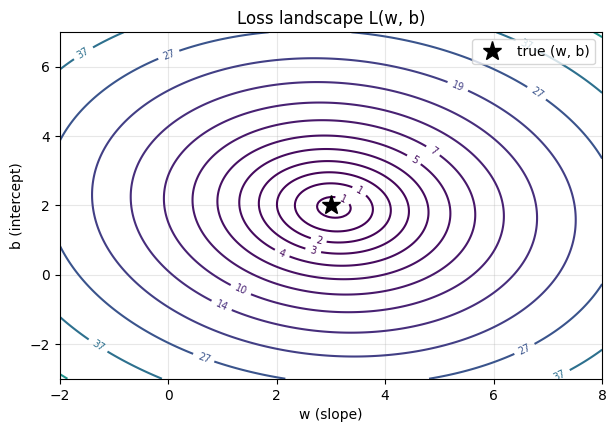

In [4]:
W, B = np.meshgrid(np.linspace(-2, 8, 200), np.linspace(-3, 7, 200))
L = np.mean((W[..., None] * x + B[..., None] - y) ** 2, axis=-1)

def plot_landscape(ax=None, title="Loss landscape L(w, b)"):
    ax = ax or plt.gca()
    cs = ax.contour(W, B, L, levels=np.logspace(0, 2, 15), cmap="viridis")
    ax.clabel(cs, inline=True, fontsize=7, fmt="%.0f")
    ax.plot(TRUE_W, TRUE_B, "k*", ms=14, label="true (w, b)")
    ax.set_xlabel("w (slope)"); ax.set_ylabel("b (intercept)"); ax.set_title(title)
    return ax

plot_landscape(); plt.legend(); plt.show()

## 3. The gradient: which way is downhill?

Imagine standing on that landscape in thick fog. You can't see the bottom, but you *can* feel the slope under your feet. The **gradient** is exactly that: a vector of partial derivatives pointing in the direction of steepest **increase**. Stepping in the **opposite** direction takes you downhill.

Using the chain rule on the MSE:

$$\frac{\partial L}{\partial w} = \frac{2}{n}\sum_i (\hat{y}_i - y_i)\,x_i \qquad \frac{\partial L}{\partial b} = \frac{2}{n}\sum_i (\hat{y}_i - y_i)$$

In words: take each prediction's error, weight it by the input (for $w$) or by 1 (for $b$), and average.

In [5]:
def gradient(w, b, x, y):
    error = predict(w, b, x) - y
    dw = 2 * np.mean(error * x)
    db = 2 * np.mean(error)
    return dw, db

print("Gradient at (0, 0):", np.round(gradient(0, 0, x, y), 3))

Gradient at (0, 0): [-6.012 -4.385]


> ⏸️ **Pause and predict:** at $(w, b) = (0, 0)$ both gradient components are negative. What does that tell you about which way $w$ and $b$ should move?

**Always check your gradient.** Hand-derived gradients are a classic source of silent bugs. The derivative is the slope over a tiny step, so we can estimate it numerically with *finite differences* and compare:

$$\frac{\partial L}{\partial w} \approx \frac{L(w + \varepsilon, b) - L(w - \varepsilon, b)}{2\varepsilon}$$

In [6]:
def numerical_gradient(w, b, x, y, eps=1e-5):
    dw = (mse_loss(w + eps, b, x, y) - mse_loss(w - eps, b, x, y)) / (2 * eps)
    db = (mse_loss(w, b + eps, x, y) - mse_loss(w, b - eps, x, y)) / (2 * eps)
    return dw, db

for point in [(0.0, 0.0), (5.0, -1.0), (2.5, 2.5)]:
    a, n_ = np.array(gradient(*point, x, y)), np.array(numerical_gradient(*point, x, y))
    print(f"at {point}: analytic {np.round(a, 5)}  numerical {np.round(n_, 5)}  match={np.allclose(a, n_)}")

at (0.0, 0.0): analytic [-6.01179 -4.38544]  numerical [-6.01179 -4.38544]  match=True
at (5.0, -1.0): analytic [ 3.14873 -5.57447]  numerical [ 3.14873 -5.57447]  match=True
at (2.5, 2.5): analytic [-0.94495  1.02004]  numerical [-0.94495  1.02004]  match=True


## 4. Gradient descent: take a step, repeat

The whole algorithm fits in one line. Start anywhere and repeatedly step against the gradient:

$$w \leftarrow w - \eta\,\frac{\partial L}{\partial w} \qquad b \leftarrow b - \eta\,\frac{\partial L}{\partial b}$$

$\eta$ (eta) is the **learning rate**: how big a step to take.

In [7]:
def gradient_descent(x, y, lr, steps, w0=-1.0, b0=6.0):
    w, b = w0, b0
    history = [(w, b, mse_loss(w, b, x, y))]
    for _ in range(steps):
        dw, db = gradient(w, b, x, y)
        w, b = w - lr * dw, b - lr * db
        history.append((w, b, mse_loss(w, b, x, y)))
    return np.array(history)

hist = gradient_descent(x, y, lr=0.1, steps=50)
w_gd, b_gd, loss_gd = hist[-1]
print(f"After 50 steps: w = {w_gd:.3f}, b = {b_gd:.3f}, loss = {loss_gd:.3f}")

After 50 steps: w = 3.055, b = 1.945, loss = 0.911


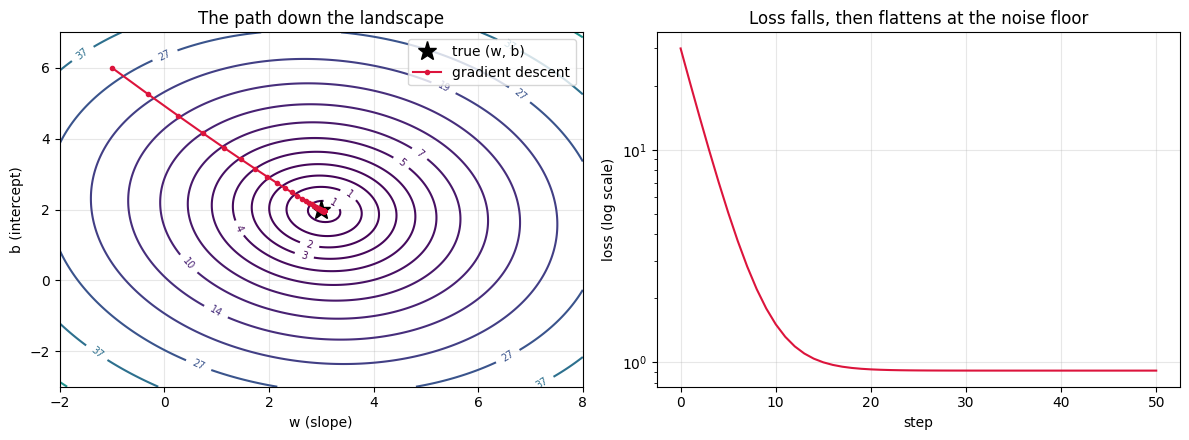

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
plot_landscape(ax1, "The path down the landscape")
ax1.plot(hist[:, 0], hist[:, 1], "o-", color="crimson", ms=3, label="gradient descent")
ax1.legend()
ax2.plot(hist[:, 2], color="crimson")
ax2.set_yscale("log"); ax2.set_xlabel("step"); ax2.set_ylabel("loss (log scale)")
ax2.set_title("Loss falls, then flattens at the noise floor")
plt.tight_layout(); plt.show()

**What just happened:** each step moved *perpendicular to the contour lines*, the steepest way down. Steps are big when the slope is steep and shrink automatically as the ground flattens near the bottom. The loss stops at about 1, not 0, because our data has noise with variance 1 that no line can explain.

## 5. The learning rate: the most important knob

> ⏸️ **Pause and predict:** what happens with a learning rate 10× smaller (0.01)? And something large, like 1.1?

  too small (0.01): final w=    1.341  b=    3.553  loss=5.79
  just right (0.1): final w=    3.055  b=    1.945  loss=0.911
     too big (1.1): final w=  -34.992  b=  -58.709  loss=5.4e+03


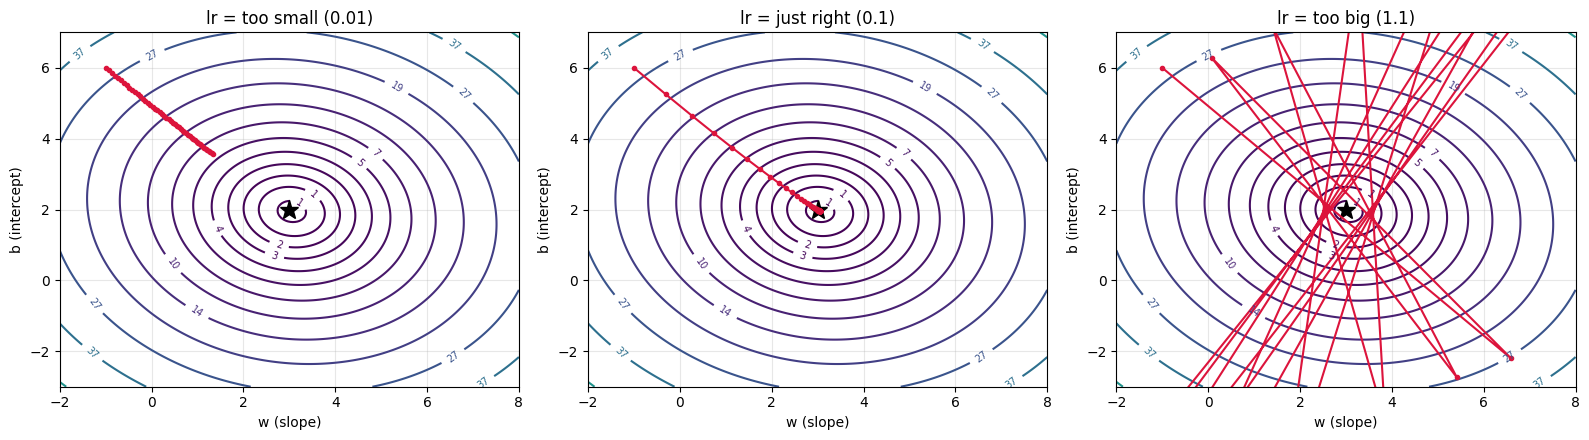

In [9]:
rates = {"too small (0.01)": 0.01, "just right (0.1)": 0.1, "too big (1.1)": 1.1}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, lr) in zip(axes, rates.items()):
    h = gradient_descent(x, y, lr=lr, steps=15 if lr > 1 else 50)
    plot_landscape(ax, f"lr = {name}")
    ax.plot(h[:, 0], h[:, 1], "o-", color="crimson", ms=3)
    ax.set_xlim(-2, 8); ax.set_ylim(-3, 7)
    print(f"{name:>18}: final w={h[-1,0]:9.3f}  b={h[-1,1]:9.3f}  loss={h[-1,2]:.3g}")
plt.tight_layout(); plt.show()

- **Too small:** every step is in the right direction, but after 50 steps we're still far from the bottom. That's wasted compute.
- **Just right:** we get there quickly.
- **Too big:** each step *overshoots* past the valley to a higher point on the other side, and the overshoot grows each time. The loss **explodes**. If you see a NaN loss in a real training run, this is the first suspect.

For this problem we can work out the limit exactly: with standardized inputs the bowl's curvature is about 2 in every direction, so any learning rate above $2 / 2 = 1$ diverges.

## 6. Sanity check: the exact answer

For linear regression specifically, calculus gives a **closed-form** solution (ordinary least squares), with no iteration needed. Gradient descent should land on the same answer.

In [10]:
X = np.column_stack([x, np.ones_like(x)])          # design matrix: [x, 1]
(w_ols, b_ols), *_ = np.linalg.lstsq(X, y, rcond=None)

print(f"Closed form (OLS): w = {w_ols:.4f}, b = {b_ols:.4f}")
print(f"Gradient descent:  w = {w_gd:.4f}, b = {b_gd:.4f}")
print(f"True values:       w = {TRUE_W:.4f}, b = {TRUE_B:.4f}")

Closed form (OLS): w = 3.0551, b = 1.9450
Gradient descent:  w = 3.0548, b = 1.9452
True values:       w = 3.0000, b = 2.0000


Gradient descent matches OLS. Neither exactly equals the true (3, 2): with only 100 noisy points, the *best possible* line for this sample is slightly off. That's the data's limit, not the algorithm's.

**So why bother with gradient descent?** The closed form only exists for a few simple models. A neural network has no formula for its best weights, but it still has a loss and a gradient. Gradient descent works for both.

## 7. Stochastic gradient descent (what's used in practice)

Computing the gradient over *all* the data on every step gets expensive when you have millions of examples. **Stochastic / mini-batch gradient descent** estimates the gradient from a small random batch instead. Each step is noisier but far cheaper.

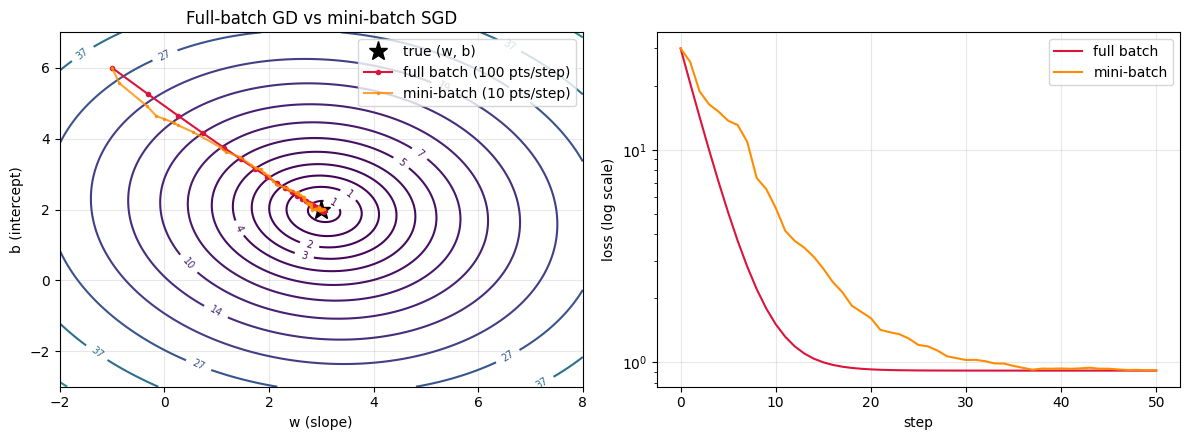

SGD final: w = 3.045, b = 2.006


In [11]:
def sgd(x, y, lr, epochs, batch_size, w0=-1.0, b0=6.0, seed=0):
    r = np.random.default_rng(seed)
    w, b = w0, b0
    history = [(w, b, mse_loss(w, b, x, y))]
    for _ in range(epochs):
        order = r.permutation(len(x))                 # shuffle each pass over the data
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            dw, db = gradient(w, b, x[idx], y[idx])   # gradient from the batch only
            w, b = w - lr * dw, b - lr * db
            history.append((w, b, mse_loss(w, b, x, y)))
    return np.array(history)

h_sgd = sgd(x, y, lr=0.05, epochs=5, batch_size=10)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
plot_landscape(ax1, "Full-batch GD vs mini-batch SGD")
ax1.plot(hist[:, 0], hist[:, 1], "o-", color="crimson", ms=3, label="full batch (100 pts/step)")
ax1.plot(h_sgd[:, 0], h_sgd[:, 1], ".-", color="darkorange", ms=3, alpha=0.8, label="mini-batch (10 pts/step)")
ax1.legend()
ax2.plot(hist[:, 2], color="crimson", label="full batch")
ax2.plot(h_sgd[:, 2], color="darkorange", label="mini-batch")
ax2.set_yscale("log"); ax2.set_xlabel("step"); ax2.set_ylabel("loss (log scale)"); ax2.legend()
plt.tight_layout(); plt.show()
print(f"SGD final: w = {h_sgd[-1,0]:.3f}, b = {h_sgd[-1,1]:.3f}")

The mini-batch path wobbles because each batch gives a slightly different view of the slope, but it still heads to the same valley, and each step only looked at 10 points. Real deep-learning training is this loop, plus refinements such as momentum and Adam, at a much larger scale.

## Recap

| Concept | One-line meaning |
|---|---|
| Model | A function with adjustable parameters ($\hat{y} = wx + b$) |
| Loss | One number for how wrong the parameters are (MSE) |
| Gradient | Direction of steepest uphill; step the opposite way |
| Learning rate | Step size: too small is slow, too big diverges |
| Closed form | An exact answer, only available for simple models |
| SGD | Estimate the gradient from small batches: cheaper, noisier, used everywhere |

## Try it yourself

1. Increase the noise in section 1 from 1 to 3. What happens to the final loss, and to how close $w, b$ get to (3, 2)?
2. Find the largest learning rate that still converges. Does it match the "limit of 1" from section 5?
3. Multiply `x` by 10 before training (unstandardized input). What happens to the safe learning rate, and why? *(Hint: look at the shape of the bowl.)*
4. Add a quadratic term, $\hat{y} = w_2x^2 + w_1x + b$, and derive its gradient. Use the numerical check from section 3 to confirm it.